In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits import mplot3d
import matplotlib.ticker as mticker
from sklearn.neighbors import KNeighborsRegressor
import plotly.express as px
import os
import re
import warnings
warnings.filterwarnings("ignore")

# Showing Internal Standard Drift

In [2]:
from sklearn.preprocessing import normalize

In [3]:
path_dict = {"05_06_2025" : {"PP_cell_A1_5" : "Standard_785", "PP_cell_A1_5-1": "Standard_785", 
                             "PP_cell_A2_5" : "Standard_785", "PP_cell_A2_5-1": "Standard_785",
                             "PP_cell_A3_5" : "Standard_785", "PP_cell_A3_5-1": "Standard_785",
                             
                             "CBG_cell_A1_5" : "Standard_785-1", "CBG_cell_A1_5-1": "Standard_785-1",
                             "CBG_cell_A2_5" : "Standard_785-1", "CBG_cell_A2_5-1": "Standard_785-1",
                             "CBG_cell_A3_5" : "Standard_785-1", "CBG_cell_A3_5-1": "Standard_785-1", 
                            },

"05_07_2025" :  {"PP_cell_C1_5" : "Standard_785-3", "PP_cell_C1_5-1": "Standard_785-3",
                 "PP_cell_C2_5" : "Standard_785-3", "PP_cell_C2_5-1": "Standard_785-4",
                 "PP_cell_C3_5" : "Standard_785-4", "PP_cell_C3_5-1": "Standard_785-4",
                 
                 "CBG_cell_C1_5" : "Standard_785-4", "CBG_cell_C1_5-1": "Standard_785-4",
                 "CBG_cell_C2_5" : "Standard_785-4", "CBG_cell_C2_5-1": "Standard_785-4",
                 "CBG_cell_C3_5" : "Standard_785-4", "CBG_cell_C3_5-1": "Standard_785-4",
                 
                 "PP_cell_A1_24" : "Standard_785", "PP_cell_A1_24-1": "Standard_785",
                 "PP_cell_A2_24" : "Standard_785", "PP_cell_A2_24-1": "Standard_785",
                 "PP_cell_A3_24" : "Standard_785", "PP_cell_A3_24-1": "Standard_785",
                 
                 "CBG_cell_A1_24" : "Standard_785-1", "CBG_cell_A1_24-1": "Standard_785-1",
                 "CBG_cell_A2_24" : "Standard_785-2", "CBG_cell_A2_24-1": "Standard_785-2",
                 "CBG_cell_A3_24" : "Standard_785-2", "CBG_cell_A3_24-1": "Standard_785-2"
                },
             
"05_08_2025" :  {"PP_cell_A1_48" : "Standard_785", "PP_cell_A1_48-1": "Standard_785",
                 "PP_cell_A2_48" : "Standard_785", "PP_cell_A2_48-1": "Standard_785",
                 "PP_cell_A3_48" : "Standard_785", "PP_cell_A3_48-1": "Standard_785",
                 
                 "CBG_cell_A1_48" : "Standard_785-1", "CBG_cell_A1_48-1": "Standard_785-1",
                 "CBG_cell_A2_48" : "Standard_785-1", "CBG_cell_A2_48-1": "Standard_785-1",
                 "CBG_cell_A3_48" : "Standard_785-1", "CBG_cell_A3_48-1": "Standard_785-1",
                 
                 "PP_cell_C1_24" : "Standard_785-2", "PP_cell_C1_24-1": "Standard_785-2",
                 "PP_cell_C2_24" : "Standard_785-2", "PP_cell_C2_24-1": "Standard_785-2",
                 "PP_cell_C3_24" : "Standard_785-2", "PP_cell_C3_24-1": "Standard_785-2"
                },
             
"05_09_2025" :  {"PP_cell_C1_48" : "Standard_785-1", "PP_cell_C1_48-1": "Standard_785-1",
                 "PP_cell_C2_48" : "Standard_785-1", "PP_cell_C2_48-1": "Standard_785-1",
                 "PP_cell_C3_48" : "Standard_785-1", "PP_cell_C3_48-1": "Standard_785-1",
                 
                 "CBG_cell_C1_48" : "Standard_785-2", "CBG_cell_C1_48-1": "Standard_785-2",
                 "CBG_cell_C2_48" : "Standard_785-2", "CBG_cell_C2_48-1": "Standard_785-2",
                 "CBG_cell_C3_48" : "Standard_785-2", "CBG_cell_C3_48-1": "Standard_785-2",
                 
                 "CBG_cell_C1_24" : "Standard_785", "CBG_cell_C1_24-1": "Standard_785",
                 "CBG_cell_C2_24" : "Standard_785", "CBG_cell_C2_24-1": "Standard_785",
                 "CBG_cell_C3_24" : "Standard_785", "CBG_cell_C3_24-1": "Standard_785"
                }
            }

In [4]:
standards_spectra = {}
for k in list(path_dict.keys()):
    path = "Raw Raman Data\\" + k
    standard_scans = path_dict[k]
    dir_list = os.listdir(path)
    
    standard_attri = {}

    stand_files = np.unique(list(standard_scans.values()))

    for i in stand_files:
        file = path + "\\" + i + ".txt"
        df = pd.read_table(file).dropna(axis = 1).rename(
        columns={"#Wave": "Wavelength", "Unnamed: 1": "Intensity"})

        temp_df = np.array(df)
        a = normalize(temp_df[:,1].reshape(-1,1), axis = 0)
        temp_df[:,1] = a.reshape(-1,)

        bool_600 = temp_df[:,0] >= 540
        bool_400 = temp_df[:,0] >= 500
        start = np.argmin(bool_600) - 1
        end = np.argmin(bool_400)

        standard = temp_df[start:end, :]
        standard = np.flip(standard, axis = 0)
#         a = normalize(standard[:,1].reshape(-1,1), axis = 0)
#         standard[:,1] = a.reshape(-1,)
        standards_spectra[file] = standard

In [5]:
key = list(standards_spectra.keys())

for i in key:
    ids = np.argmax(standards_spectra[i][:,1])
    print(standards_spectra[i][ids,0])

521.166016
521.098633
521.250977
521.117188
520.121094
520.121094
521.271484
520.070313
520.024414
520.024414
521.204102
521.362305
520.12793


In [6]:
vals = list(standards_spectra.values())

s1 = 0
s2 = 0
norm = 0

for i in range(len(vals)):
    for j in range(len(vals)):
        temp = np.linalg.norm(vals[i] - vals[j])
        if temp > norm:
            norm = temp
            s1 = i
            s2 = j

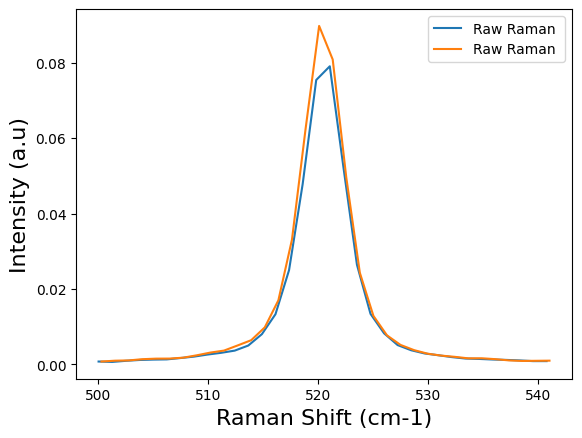

In [7]:
plt.plot(vals[s1][:,0], vals[s1][:,1], label = key[s1][:10])
plt.plot(vals[s2][:,0], vals[s2][:,1], label = key[s2][:10])
plt.xlabel("Raman Shift (cm-1)", fontsize = 16)
plt.ylabel("Intensity (a.u)", fontsize = 16)
plt.legend()

# Selecting common datapoints 

## Find the common wavenumber range between the datasets

In [8]:
wavenumber = {}

In [9]:
path_dict = {"05_06_2025" : {"PP_cell_A1_5" : "Standard_785", "PP_cell_A1_5-1": "Standard_785", 
                             "PP_cell_A2_5" : "Standard_785", "PP_cell_A2_5-1": "Standard_785",
                             "PP_cell_A3_5" : "Standard_785", "PP_cell_A3_5-1": "Standard_785",
                             
                             "CBG_cell_A1_5" : "Standard_785-1", "CBG_cell_A1_5-1": "Standard_785-1",
                             "CBG_cell_A2_5" : "Standard_785-1", "CBG_cell_A2_5-1": "Standard_785-1",
                             "CBG_cell_A3_5" : "Standard_785-1", "CBG_cell_A3_5-1": "Standard_785-1", 
                            },

"05_07_2025" :  {"PP_cell_C1_5" : "Standard_785-3", "PP_cell_C1_5-1": "Standard_785-3",
                 "PP_cell_C2_5" : "Standard_785-3", "PP_cell_C2_5-1": "Standard_785-4",
                 "PP_cell_C3_5" : "Standard_785-4", "PP_cell_C3_5-1": "Standard_785-4",
                 
                 "CBG_cell_C1_5" : "Standard_785-4", "CBG_cell_C1_5-1": "Standard_785-4",
                 "CBG_cell_C2_5" : "Standard_785-4", "CBG_cell_C2_5-1": "Standard_785-4",
                 "CBG_cell_C3_5" : "Standard_785-4", "CBG_cell_C3_5-1": "Standard_785-4",
                 
                 "PP_cell_A1_24" : "Standard_785", "PP_cell_A1_24-1": "Standard_785",
                 "PP_cell_A2_24" : "Standard_785", "PP_cell_A2_24-1": "Standard_785",
                 "PP_cell_A3_24" : "Standard_785", "PP_cell_A3_24-1": "Standard_785",
                 
                 "CBG_cell_A1_24" : "Standard_785-1", "CBG_cell_A1_24-1": "Standard_785-1",
                 "CBG_cell_A2_24" : "Standard_785-2", "CBG_cell_A2_24-1": "Standard_785-2",
                 "CBG_cell_A3_24" : "Standard_785-2", "CBG_cell_A3_24-1": "Standard_785-2"
                },
             
"05_08_2025" :  {"PP_cell_A1_48" : "Standard_785", "PP_cell_A1_48-1": "Standard_785",
                 "PP_cell_A2_48" : "Standard_785", "PP_cell_A2_48-1": "Standard_785",
                 "PP_cell_A3_48" : "Standard_785", "PP_cell_A3_48-1": "Standard_785",
                 
                 "CBG_cell_A1_48" : "Standard_785-1", "CBG_cell_A1_48-1": "Standard_785-1",
                 "CBG_cell_A2_48" : "Standard_785-1", "CBG_cell_A2_48-1": "Standard_785-1",
                 "CBG_cell_A3_48" : "Standard_785-1", "CBG_cell_A3_48-1": "Standard_785-1",
                 
                 "PP_cell_C1_24" : "Standard_785-2", "PP_cell_C1_24-1": "Standard_785-2",
                 "PP_cell_C2_24" : "Standard_785-2", "PP_cell_C2_24-1": "Standard_785-2",
                 "PP_cell_C3_24" : "Standard_785-2", "PP_cell_C3_24-1": "Standard_785-2"
                },
             
"05_09_2025" :  {"PP_cell_C1_48" : "Standard_785-1", "PP_cell_C1_48-1": "Standard_785-1",
                 "PP_cell_C2_48" : "Standard_785-1", "PP_cell_C2_48-1": "Standard_785-1",
                 "PP_cell_C3_48" : "Standard_785-1", "PP_cell_C3_48-1": "Standard_785-1",
                 
                 "CBG_cell_C1_48" : "Standard_785-2", "CBG_cell_C1_48-1": "Standard_785-2",
                 "CBG_cell_C2_48" : "Standard_785-2", "CBG_cell_C2_48-1": "Standard_785-2",
                 "CBG_cell_C3_48" : "Standard_785-2", "CBG_cell_C3_48-1": "Standard_785-2",
                 
                 "CBG_cell_C1_24" : "Standard_785", "CBG_cell_C1_24-1": "Standard_785",
                 "CBG_cell_C2_24" : "Standard_785", "CBG_cell_C2_24-1": "Standard_785",
                 "CBG_cell_C3_24" : "Standard_785", "CBG_cell_C3_24-1": "Standard_785"
                }
            }

In [10]:
for k in list(path_dict.keys()):
    print(k)
    path = "Raw Raman Data\\" + k
    standard_scans = path_dict[k]
    dir_list = os.listdir(path)
    
    standard_attri = {}

    stand_files = np.unique(list(standard_scans.values()))

    for i in stand_files:
        file = path + "\\" + i + ".txt"
        df = pd.read_table(file).dropna(axis = 1).rename(
        columns={"#Wave": "Wavelength", "Unnamed: 1": "Intensity"})

        temp_df = np.array(df)

        bool_600 = temp_df[:,0] >= 540
        bool_400 = temp_df[:,0] >= 500
        start = np.argmin(bool_600) - 1
        end = np.argmin(bool_400)

        standard = temp_df[start:end, :]
        standard[:,1] = standard[:,1] - np.min(standard[:,1])
        standard = np.flip(standard, axis = 0)
        peak_adju = 520.5 - standard[np.argmax(standard[:,1]),0]

        standard_attri[i] = [peak_adju, np.max(standard), np.trapz(standard[:,1], standard[:,0])]


    filelist = []

    for i in range(len(dir_list)):
        if "Standard" not in dir_list[i]:
            file = path + "\\" + dir_list[i]
            filelist.append(file)

    for i in range(len(filelist)):
        #print(filelist[i])
        #print("~~~~~~~~~~~~~~~~~~~~~~")
        if ".txt" in filelist[i]:
            df = pd.read_table(filelist[i]).dropna(axis = 1).rename(columns={"#X": "#X", "Unnamed: 1": "#Y",
                                                                             "#Y" : "Wavelength", "Unnamed: 3": "Intensity"})

            ids, cnt = np.unique(np.array(df["Wavelength"]), return_counts = True)
            assert(len(np.unique(cnt)) == 1)

            num_scans = np.unique(cnt)[0]
            scan_list = np.split(np.array(df.iloc[:,2:], dtype = np.float64), num_scans)

            a = filelist[i].split("\\")[2].split(".")
            b = a[0]
            st_att = standard_attri[standard_scans[b]]

            temp = scan_list[0][:,0] + st_att[0]
            wv = []
            for x in temp:
                wv.append(round(x))

            wavenumber[filelist[i]] = np.unique(wv)
    
    print("###############")

05_06_2025
###############
05_07_2025
###############
05_08_2025
###############
05_09_2025
###############


Text(0.5, 1.0, 'Internal Silicone Standard')

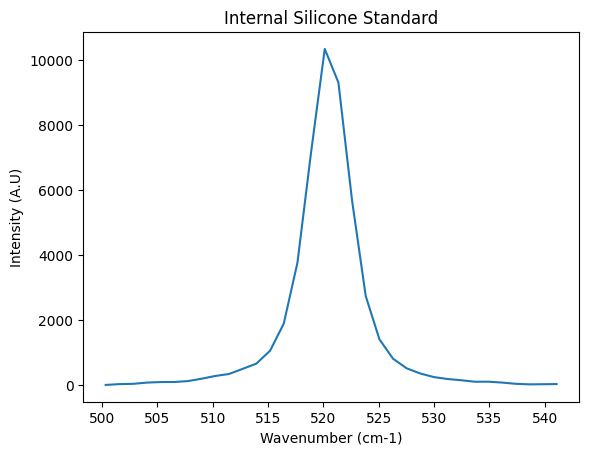

In [11]:
plt.plot(standard[:,0], standard[:,1])
plt.xlabel("Wavenumber (cm-1)")
plt.ylabel("Intensity (A.U)")
plt.title("Internal Silicone Standard")

In [12]:
standard_attri

{'Standard_785': [-0.7041020000000344, 15756.595353, 87439.7202072495],
 'Standard_785-1': [-0.8623049999999921, 8672.945747, 50085.307679520905],
 'Standard_785-2': [0.3720700000000079, 10341.398895, 59607.74603423065]}

In [13]:
master_list  = []

for i in wavenumber.values():
    master_list.extend(i)

ids, cnt = np.unique(master_list, return_counts = True)
num_files = len(wavenumber.values())


wv_considered = []
wv_not_considered = []

for i in range(len(ids)):
    if cnt[i] != num_files:
        wv_not_considered.append(ids[i])
    elif cnt[i] == num_files:
        wv_considered.append(ids[i])

wv_considered = np.array(wv_considered)

In [14]:
num_files

72

## Make the Raman Dataset

In [15]:
final_raw_raman_data = []
bacteria_type =[]
bacteria_age = []
bacteria_metabolic = []
raman_intensity = [] 
raman_auc = []
file_list = []
biological_rep = []
technical_rep = []

for k in list(path_dict.keys()):
    path = "Raw Raman Data\\" + k
    standard_scans = path_dict[k]
    dir_list = os.listdir(path)
    
    standard_attri = {}

    stand_files = np.unique(list(standard_scans.values()))

    for i in stand_files:
        file = path + "\\" + i + ".txt"
        df = pd.read_table(file).dropna(axis = 1).rename(
        columns={"#Wave": "Wavelength", "Unnamed: 1": "Intensity"})

        temp_df = np.array(df)

        bool_600 = temp_df[:,0] >= 540
        bool_400 = temp_df[:,0] >= 500
        start = np.argmin(bool_600) - 1
        end = np.argmin(bool_400)

        standard = temp_df[start:end, :]
        standard[:,1] = standard[:,1] - np.min(standard[:,1])
        standard = np.flip(standard, axis = 0)
        peak_adju = 520.5 - standard[np.argmax(standard[:,1]),0]

        standard_attri[i] = [peak_adju, np.max(standard), np.trapz(standard[:,1], standard[:,0])]


    filelist = []

    for i in range(len(dir_list)):
        if "Standard" not in dir_list[i]:
            file = path + "\\" + dir_list[i]
            filelist.append(file)

    for i in range(len(filelist)):
        if ".txt" in filelist[i]:
            df = pd.read_table(filelist[i]).dropna(axis = 1).rename(columns={"#X": "#X", "Unnamed: 1": "#Y",
                                                                             "#Y" : "Wavelength", "Unnamed: 3": "Intensity"})

            ids, cnt = np.unique(np.array(df["Wavelength"]), return_counts = True)
            assert(len(np.unique(cnt)) == 1)

            num_scans = np.unique(cnt)[0]
            scan_list = np.split(np.array(df.iloc[:,2:], dtype = np.float64), num_scans)

            a = filelist[i].split("\\")[2].split(".")
            b = a[0]
            st_att = standard_attri[standard_scans[b]]

            if "-1" in b.split("_")[3]:
                tr = 6
            else:
                tr = 1
                
            for j in scan_list:
                wv = np.round(j[:,0] + st_att[0])
                temp = j[:,1]

                ids, pos, cnt = np.unique(wv, return_index = True, return_counts = True)
                data = []

                for k in range(len(ids)):
                    if cnt[k] > 1:
                        data.append(np.mean(temp[pos[k]:pos[k]+cnt[k]]))
                    else:
                        data.append(temp[pos[k]])

                wv_full = ids

                wv_final = []
                data_final = []

                for l in range(len(wv_full)):
                    if wv_full[l] in wv_considered:
                        wv_final.append(wv_full[l])
                        data_final.append(data[l])

                final_raw_raman_data.append(data_final)
                bacteria_type.append(b.split("_")[0])
                bacteria_age.append(b.split("_")[-1].split("-")[0])
                bacteria_metabolic.append(b.split("_")[2][0])
                raman_intensity.append(st_att[1])
                raman_auc.append(st_att[2])
                file_list.append(path.split("\\")[1])
                biological_rep.append(int(b.split("_")[2][1]))
                technical_rep.append(tr)
                tr += 1

Text(0.5, 1.0, 'Bacteria Raw Raman Spectra')

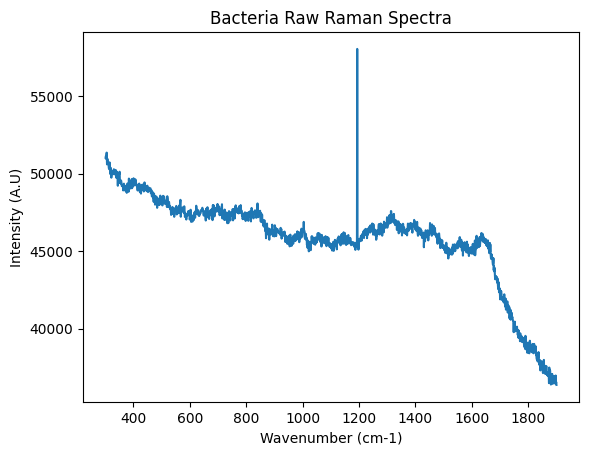

In [16]:
plt.plot(scan_list[0][:,0], scan_list[0][:,1])
plt.xlabel("Wavenumber (cm-1)")
plt.ylabel("Intensity (A.U)")
plt.title("Bacteria Raw Raman Spectra")

In [17]:
final_raw_raman_data = np.array(final_raw_raman_data)

data = {"Bacteria Type" : bacteria_type,
        "Bacteria Age" : bacteria_age,
        "Bacteria Metabolic" : bacteria_metabolic,
        "Standard Intensity" : raman_intensity,
        "Standard Area" : raman_auc,
        "Day of Collection" : file_list,
        "Biological Replicate" : biological_rep,
        "Technical Replicate" : technical_rep}

df = pd.DataFrame(data)
for k in range(len(wv_final)):
    df[wv_final[k]] = final_raw_raman_data[:,k]

In [18]:
df

,Bacteria Type,Bacteria Age,Bacteria Metabolic,Standard Intensity,Standard Area,Day of Collection,Biological Replicate,Technical Replicate,303.0,304.0,...,1891.0,1892.0,1893.0,1894.0,1895.0,1896.0,1897.0,1898.0,1899.0,1900.0
0,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,6,9690.354492,9897.358398,...,2632.366455,2572.550293,2592.261475,2515.951416,2568.589355,2692.611816,2536.662109,2721.135498,2578.861328,2623.322510
1,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,7,9479.474609,9414.660156,...,2451.391357,2438.163330,2479.792969,2384.254883,2373.749756,2415.390869,2402.142090,2397.125488,2378.375000,2345.882080
2,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,8,11910.680664,11826.126953,...,2829.793945,2838.581787,2784.280762,2749.163818,2755.196289,2832.594727,2852.372070,2787.035889,2826.036621,2722.212158
3,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,9,13743.716797,13647.403320,...,4033.553223,4116.628906,4122.930176,4074.359619,4102.607910,4073.227051,3994.418945,4028.159424,4105.854980,4134.136230
4,CBG,5,A,9637.485741,56928.534394,05_06_2025,1,10,16047.178711,16038.588867,...,4499.701660,4541.730957,4506.968750,4436.524902,4475.821777,4570.029297,4384.252441,4404.340332,4517.813965,4592.874512
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,PP,48,C,8672.945747,50085.307680,05_09_2025,3,1,50935.437500,51348.371094,...,36682.957031,36539.375000,36927.898438,36787.046875,36860.187500,36461.253906,36622.203125,36980.914063,36508.482422,36374.742188
356,PP,48,C,8672.945747,50085.307680,05_09_2025,3,2,44410.351563,44067.359375,...,35311.937500,35047.410156,35345.117188,34866.480469,35224.636719,35053.199219,34961.300781,35064.320313,35033.519532,35240.261719
357,PP,48,C,8672.945747,50085.307680,05_09_2025,3,3,53247.000000,53258.875000,...,35698.566406,35842.757813,35759.328125,35483.804688,35699.386719,35577.445313,35757.437500,35492.671875,35787.466797,35561.652344
358,PP,48,C,8672.945747,50085.307680,05_09_2025,3,4,55195.605469,55104.480469,...,40573.906250,40466.746094,39931.617188,40743.410156,40378.257813,40114.515625,39776.546875,40649.351563,40110.714843,40484.136719


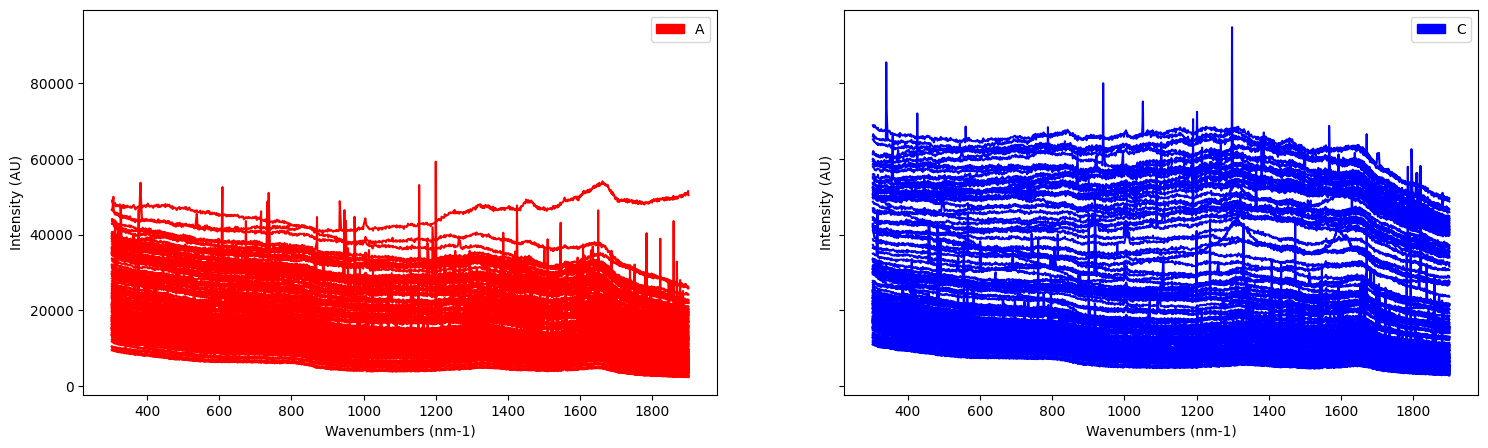

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharex = True, sharey = True)
ax = axes.ravel()

final_data = np.array(df.iloc[:,8:])

red_patch = mpatches.Patch(color='red', label='A')
blue_patch = mpatches.Patch(color='blue', label='C')

for i in range(len(final_data)):
    if df["Bacteria Metabolic"][i] == "A":
        ax[0].plot(wv_final, final_data[i,:], color = "red")
        ax[0].legend(handles=[red_patch])
        ax[0].set_xlabel("Wavenumbers (nm-1)")
        ax[0].set_ylabel("Intensity (AU)")


    else:
        ax[1].plot(wv_final, final_data[i,:], color = "blue")
        ax[1].legend(handles=[blue_patch])
        ax[1].set_xlabel("Wavenumbers (nm-1)")
        ax[1].set_ylabel("Intensity (AU)")

In [20]:
xl_name = "Raw_Raman_Dataset_2025.xlsx"
df.to_excel(xl_name)